# Stories Coffee: Slow Sellers as Discounted Add-ons

**Question:** should Stories use its slow-selling items as discounted add-ons ("add a soup to any drink for 30% off"), and which ones?

`06_bundle_offers.ipynb` rejected slow sellers because they have low margins. That test was incomplete. The cost of a discount is mostly paid to customers who **already** buy the item, and slow sellers have few of those. This notebook redoes the comparison properly. `02` is left as it was; this notebook replaces its slow-seller point.

Throughout, **observed facts** (computed from the data) are kept separate from **assumptions** (marked *Assumption*) and **estimates** (marked *Estimate*).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import norm

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
# Repository layout: run from the repo root or notebooks/; data comes from STORIES_DATA or data/
ROOT = Path.cwd()
if not (ROOT / "reports").exists(): ROOT = ROOT.parent
DATA = Path(os.environ.get("STORIES_DATA", ROOT / "data" / "stories_transactions.csv"))
FIG = ROOT / "figures" / "slow_seller_addons"; FIG.mkdir(parents=True, exist_ok=True)

# One fixed colour per branch, same as 01_eda.ipynb
BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "font.size": 9, "legend.frameon": False, "lines.linewidth": 2,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Load the data

In [2]:
raw = pd.read_csv(DATA, dtype={"Customer ID": "string"})
raw = raw.rename(columns={
    "Transaction ID": "txn", "Date": "date", "Time": "time", "Branch": "branch",
    "Customer ID": "cust", "Order Type": "order_type", "Product": "product",
    "Category": "category", "Quantity": "qty", "Unit Price (USD)": "price",
    "Discount Rate": "disc", "Unit Cost (USD)": "cost",
    "Line Revenue (USD)": "rev", "Line Gross Profit (USD)": "gp"})
raw = raw[~raw.duplicated()].copy()
raw["ts"] = pd.to_datetime(raw["date"] + " " + raw["time"])
raw["date"] = pd.to_datetime(raw["date"])
raw["hour"] = raw.ts.dt.hour

DRINKS = {"Hot Coffee", "Cold Coffee", "Matcha & Tea", "Cold Drinks"}
raw["drink_units"] = np.where(raw.category.isin(DRINKS), raw.qty, 0)
raw["food_units"] = np.where(raw.category.isin(DRINKS), 0, raw.qty)
SPLIT = pd.Timestamp("2026-04-01")
raw["half"] = np.where(raw.date < SPLIT, "train", "test")

txn = raw.groupby("txn").agg(branch=("branch", "first"), date=("date", "first"), hour=("hour", "first"),
                             half=("half", "first"), order_type=("order_type", "first"),
                             lines=("product", "size"), drinks=("drink_units", "sum"), food=("food_units", "sum"),
                             rev=("rev", "sum"), gp=("gp", "sum"))
txn["cats"] = raw.groupby("txn").category.apply(set)
txn["prods"] = raw.groupby("txn")["product"].apply(set)
test_tx = txn[txn.half == "test"]
months_test = test_tx.date.dt.to_period("M").nunique()
print("line items:", len(raw), "| transactions:", len(txn), "| Apr-Jun months:", months_test)

line items: 51045 | transactions: 33887 | Apr-Jun months: 3


## 2. Which items are slow, and are they consistently slow?

**Rule:** slow sellers are the 10 products with the fewest units sold in Jan to Mar. We check they are still slow in Apr to Jun, and whether they are cheap or expensive within their category.

In [3]:
prod = raw.groupby("product").agg(category=("category", "first"), price=("price", "mean"), cost=("cost", "mean"))
prod["gm"] = 1 - prod.cost / prod.price
prod["units_train"] = raw[raw.half == "train"].groupby("product").qty.sum()
prod["units_test"] = raw[raw.half == "test"].groupby("product").qty.sum()
prod["rank_train"] = prod.units_train.rank(method="first").astype(int)
prod["rank_test"] = prod.units_test.rank(method="first").astype(int)
prod["price_vs_category"] = prod.price / prod.groupby("category").price.transform("median")
SLOW = prod.nsmallest(10, "units_train").index.tolist()
slow = prod.loc[SLOW]
print("still in the bottom 10 in Apr-Jun:", (slow.rank_test <= 10).sum(), "of 10")
slow[["category", "price", "price_vs_category", "gm", "units_train", "units_test", "rank_test"]].round(2)

still in the bottom 10 in Apr-Jun: 9 of 10


,category,price,price_vs_category,gm,units_train,units_test,rank_test
product,,,,,,,
Soup of the Day,Meals,7.28,0.62,0.57,190,259,1
English Breakfast Tea,Matcha & Tea,3.52,0.59,0.82,205,268,2
Quinoa Bowl,Meals,11.80,1.00,0.53,210,292,3
Chicken Salad Bowl,Meals,12.64,1.07,0.49,228,324,5
Granola Yoghurt,Breakfast,7.99,0.96,0.53,254,321,4
Mint Tea,Matcha & Tea,3.71,0.62,0.81,270,361,6
Espresso,Hot Coffee,2.70,0.61,0.73,299,387,7
Tuna Sandwich,Sandwiches,8.97,0.91,0.54,305,415,8
Fresh Orange Juice,Cold Drinks,5.85,1.29,0.59,408,594,17


**Observed:** 9 of the 10 stay slow in Apr to Jun (orange juice moves up), so this is a stable pattern, not a bad month. They split into two kinds:

- **Food** (two bowls, soup, granola, tuna sandwich, blueberry muffin), with margins of 49 to 63%. The two bowls are the most expensive items on the menu at about $12 to $13; the others are at or below their category's typical price, and soup is cheap. So **price does not explain** why these sell slowly.
- **Cheap drinks** (English Breakfast tea, mint tea, espresso), with margins of 73 to 82%.

## 3. What a discount really costs

The offer is *"add item X to any order with a drink, X at 30% off"*. For each product, using Apr to Jun baskets:

- **Cost:** baskets with a drink that **already** contain X get `30% x price` off. (*Assumption, worst case:* all of them use the offer.)
- **Gain:** a drink basket **without** X that adds it because of the offer earns X's profit after the discount.
- **Break-even take-up** = cost / (number of drink baskets without X x gain per add-on).

Prices and costs are per branch, because Garden's unit costs are higher.

In [4]:
D = 0.30
host = test_tx[test_tx.drinks >= 1]
pc = raw.groupby(["branch", "product"]).agg(price=("price", "first"), cost=("cost", "first"))
rows = []
for pr in prod.index:
    has = host.prods.map(lambda s: pr in s)
    cost = upside = 0
    for br in BRANCHES:
        price, c = pc.loc[(br, pr)]
        m = (host.branch == br).values
        cost += has[m].sum() * D * price
        upside += (~has[m]).sum() * ((price - c) - D * price)
    rows.append(dict(product=pr, already_per_month=has.sum() / months_test,
                     gain_per_addon=upside / (~has).sum(), breakeven_takeup=cost / upside if upside > 0 else np.inf))
addon = prod.join(pd.DataFrame(rows).set_index("product"))
addon["slow"] = addon.index.isin(SLOW)
print("drink baskets per month, Apr-Jun:", round(len(host) / months_test))
print("median break-even take-up, slow sellers:", round(addon[addon.slow].breakeven_takeup.median(), 4),
      "| other products:", round(addon[~addon.slow].breakeven_takeup.median(), 4),
      "| highest on the menu:", round(addon.breakeven_takeup[np.isfinite(addon.breakeven_takeup)].max(), 4))
addon.sort_values("breakeven_takeup")[["category", "price", "gm", "already_per_month", "gain_per_addon", "breakeven_takeup", "slow"]].head(12).round(4)

drink baskets per month, Apr-Jun: 4389
median break-even take-up, slow sellers: 0.0149 | other products: 0.0383 | highest on the menu: 0.1006


,category,price,gm,already_per_month,gain_per_addon,breakeven_takeup,slow
product,,,,,,,
Soup of the Day,Meals,7.2829,0.5656,34.3333,1.9344,0.0089,True
Granola Yoghurt,Breakfast,7.9864,0.5301,37.6667,1.8319,0.0113,True
English Breakfast Tea,Matcha & Tea,3.5195,0.8187,84.6667,1.8085,0.0115,True
Quinoa Bowl,Meals,11.7956,0.5266,41.6667,2.7273,0.0125,True
Chicken Salad Bowl,Meals,12.6412,0.4919,41.3333,2.4718,0.0146,True
Blueberry Muffin,Bakery,4.0248,0.6296,72.0000,1.3319,0.0152,True
Egg Sandwich,Breakfast,8.2800,0.5705,62.3333,2.2843,0.0157,False
Mint Tea,Matcha & Tea,3.7141,0.8091,114.3333,1.8863,0.0158,True
Tuna Sandwich,Sandwiches,8.9673,0.5356,58.3333,2.0819,0.0174,True


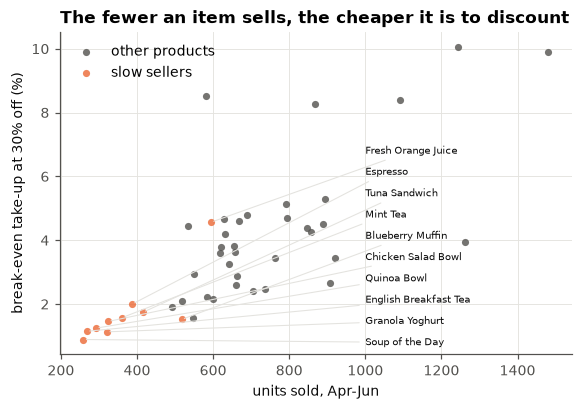

correlation, units sold vs break-even take-up: 0.75


In [5]:
fig, ax = plt.subplots(figsize=(6.0, 3.8))
fin = addon[np.isfinite(addon.breakeven_takeup)]
for is_slow, color, label in [(False, MUTED, "other products"), (True, "#eb6834", "slow sellers")]:
    s = fin[fin.slow == is_slow]
    ax.scatter(s.units_test, s.breakeven_takeup * 100, color=color, s=22, alpha=0.8, lw=0, label=label)
# slow sellers cluster in one corner, so their labels go in a column to the right with leader lines
lab = fin[fin.slow].sort_values("breakeven_takeup")
ys = np.linspace(0.8, 6.8, len(lab))
for (pr, r), y in zip(lab.iterrows(), ys):
    ax.annotate(pr, (r.units_test, r.breakeven_takeup * 100), xytext=(1000, y), textcoords="data", fontsize=6.5,
                color=INK, va="center", arrowprops=dict(arrowstyle="-", color=GRID, lw=0.7))
ax.set_xlabel("units sold, Apr-Jun"); ax.set_ylabel("break-even take-up at 30% off (%)")
ax.set_title("The fewer an item sells, the cheaper it is to discount")
ax.legend(loc="upper left"); save(fig, "10_addon_breakeven_vs_sales"); plt.show()
print("correlation, units sold vs break-even take-up:", round(fin.units_test.corr(fin.breakeven_takeup), 2))

**Observed:** slow sellers have the **lowest** break-even take-ups on the menu, because few existing buyers collect the discount. Their lower margin percentage matters less than this. The rejection in `06_bundle_offers.ipynb` looked only at margin percentage and reached the wrong conclusion.

*Caveat:* every break-even here is small, because the offer is open to every drink basket and most of them do not contain the item. So the decision does not hinge on the discount cost; it hinges on **whether customers want the item at all**, which section 7 tests.

## 4. Do the slow items fit with a drink?

An add-on offer only works if the item makes sense next to a drink. Using two-item baskets, category lift (observed / expected under independent choice) between each food category and each drink category, in both halves of the year:

In [6]:
cats2 = raw.groupby("txn").category.apply(lambda s: tuple(sorted(s)))
def cat_lift(mask):
    two = cats2[(txn.lines == 2) & mask]
    n = len(two)
    share = two.explode().value_counts() / (2 * n)
    obs = two.value_counts()
    return pd.Series({(a, b): k / (n * share[a] * share[b] * (1 if a == b else 2)) for (a, b), k in obs.items()})
lift = pd.DataFrame({"train": cat_lift(txn.half == "train"), "test": cat_lift(txn.half == "test")})
food_cats = sorted(set(slow[~slow.category.isin(DRINKS)].category))
rows = []
for fc in food_cats:
    for dc in sorted(DRINKS):
        key = tuple(sorted((fc, dc)))
        if key in lift.index:
            rows.append(dict(food=fc, drink=dc, lift_train=lift.loc[[key]].train.iloc[0], lift_test=lift.loc[[key]].test.iloc[0]))
fit = pd.DataFrame(rows)
fit.pivot_table(index="food", columns="drink", values="lift_test").round(2)

drink,Cold Coffee,Cold Drinks,Hot Coffee,Matcha & Tea
food,,,,
Bakery,1.28,0.73,1.29,1.76
Breakfast,1.06,0.95,1.10,0.94
Meals,0.98,1.74,0.98,0.72
Sandwiches,0.96,2.11,0.95,0.82


**Observed:** meals and sandwiches go strongly with **cold drinks** and much less with hot coffee or matcha. So an add-on offer for a soup, bowl or tuna sandwich should be shown to cold-drink orders, not to every drink order. Breakfast items show no strong partner.

## 5. Choosing candidates

**Rule (fixed before looking at the waste scenario):** a candidate is a slow seller that is food (the add-on goes next to a drink), stays slow in Apr to Jun, has positive profit per add-on at 30% off, and whose category has lift of at least 1.2 with some drink category in **both** halves. Candidates are ranked by gross profit per add-on. Each candidate's **comparison item** for the pilot is the best-selling non-slow product from the categories that fit the same drink, so both are shown to the same customers.

In [7]:
best = fit[(fit.lift_train >= 1.2) & (fit.lift_test >= 1.2)].sort_values("lift_test", ascending=False).drop_duplicates("food")
cand = addon[addon.slow & ~addon.category.isin(DRINKS) & (addon.rank_test <= 10) & (addon.gain_per_addon > 0)]
cand = cand.join(best.set_index("food")[["drink", "lift_test"]], on="category", how="inner").sort_values("gain_per_addon", ascending=False)
def comparator(drink):
    fits = fit[(fit.drink == drink) & (fit.lift_train >= 1.2) & (fit.lift_test >= 1.2)].food
    pool_ = addon[addon.category.isin(fits) & ~addon.slow]
    return pool_.units_test.idxmax()
cand["compare_with"] = cand.drink.map(comparator)
COMPARE = sorted(set(cand.compare_with))
print("candidates:", cand.index.tolist())
print("comparison items:", COMPARE)
pd.concat([cand, addon.loc[COMPARE]])[["category", "price", "gm", "already_per_month", "gain_per_addon", "breakeven_takeup", "drink", "lift_test", "compare_with"]].round(3)

candidates: ['Quinoa Bowl', 'Chicken Salad Bowl', 'Tuna Sandwich', 'Soup of the Day', 'Blueberry Muffin']
comparison items: ['Butter Croissant', 'Chicken Pesto Sandwich']


,category,price,gm,already_per_month,gain_per_addon,breakeven_takeup,drink,lift_test,compare_with
product,,,,,,,,,
Quinoa Bowl,Meals,11.796,0.527,41.667,2.727,0.012,Cold Drinks,1.741,Chicken Pesto Sandwich
Chicken Salad Bowl,Meals,12.641,0.492,41.333,2.472,0.015,Cold Drinks,1.741,Chicken Pesto Sandwich
Tuna Sandwich,Sandwiches,8.967,0.536,58.333,2.082,0.017,Cold Drinks,2.105,Chicken Pesto Sandwich
Soup of the Day,Meals,7.283,0.566,34.333,1.934,0.009,Cold Drinks,1.741,Chicken Pesto Sandwich
Blueberry Muffin,Bakery,4.025,0.630,72.000,1.332,0.015,Matcha & Tea,1.765,Butter Croissant
Butter Croissant,Bakery,3.717,0.655,194.667,1.308,0.040,NaN,NaN,NaN
Chicken Pesto Sandwich,Sandwiches,10.869,0.466,91.000,1.808,0.038,NaN,NaN,NaN


## 6. If slow items are thrown away, they are worth more (assumption only)

Soups, bowls and sandwiches are perishable. If some of the extra units sold through the offer would otherwise have been thrown away, each such unit also saves its cost. The data has no waste records, so the waste share `w` below is an **assumption**, shown only to size the effect. Stories' waste logs would replace it.

In [8]:
rows = []
for pr in cand.index.tolist() + COMPARE:
    unit_cost = prod.loc[pr, "cost"]
    for w in [0.0, 0.25, 0.5]:
        rows.append(dict(product=pr, waste_share=w, profit_per_100_addons=100 * (addon.loc[pr, "gain_per_addon"] + w * unit_cost)))
waste = pd.DataFrame(rows).pivot_table(index="product", columns="waste_share", values="profit_per_100_addons", sort=False)
waste.round(0)

waste_share,0.00,0.25,0.50
product,,,
Quinoa Bowl,273.0,412.0,552.0
Chicken Salad Bowl,247.0,408.0,568.0
Tuna Sandwich,208.0,312.0,416.0
Soup of the Day,193.0,273.0,352.0
Blueberry Muffin,133.0,170.0,208.0
Butter Croissant,131.0,163.0,195.0
Chicken Pesto Sandwich,181.0,326.0,471.0


## 7. A pilot that tests the real risk: do customers want the slow item?

**Design:** the same add-on offer at 30% off, alternating by week between a slow item and its comparison item, at all three branches, 4 weeks each (8 weeks in total). Both arms are shown to the same orders: cold-drink orders for meals and sandwiches, matcha or tea orders for the muffin.

**Metric:** take-up, the share of eligible baskets without the item that add it. The question is whether the slow item's take-up is close to the popular item's. If it is, the slow item is the better offer, because it costs less to discount and earns more per add-on.

How large a take-up difference can 4 weeks per arm detect (two-sided 5% test, 80% power)?

In [9]:
day = txn.groupby(["branch", "date"]).size().rename("n").reset_index()
day["dow"] = day.date.dt.dayofweek

def fit_trend(d):
    # weekly growth from a straight line on log weekly totals, then a weekday profile around that trend
    t0 = d.date.min()
    w = d.assign(week=(d.date - t0).dt.days // 7).groupby("week").n.agg(["sum", "size"])
    w = w[w["size"] == 7]
    slope = np.polyfit(w.index, np.log(w["sum"]), 1)[0]
    wk = (d.date - t0).dt.days / 7
    prof = (d.n / np.exp(slope * wk)).groupby(d.dow).mean()
    return lambda dates: prof.reindex(dates.dt.dayofweek).values * np.exp(slope * (dates - t0).dt.days / 7), slope

# re-check on unseen months: fit on Jan-Apr, test on May-Jun
F_SPLIT = pd.Timestamp("2026-05-01")
err, tot = 0, 0
for br in BRANCHES:
    f, _ = fit_trend(day[(day.branch == br) & (day.date < F_SPLIT)])
    t = day[(day.branch == br) & (day.date >= F_SPLIT)]
    err += (t.n - f(t.date)).abs().sum(); tot += t.n.sum()
print("trend forecast, May-Jun daily transactions per branch: WAPE", round(err / tot, 3))

PILOT_DATES = pd.Series(pd.date_range("2026-07-06", "2026-08-02"))
proj = pd.Series({br: fit_trend(day[day.branch == br])[0](PILOT_DATES).sum() for br in BRANCHES})
scale = proj / test_tx.groupby("branch").size()   # 4 pilot weeks relative to the whole Apr-Jun period
print("Estimate: projected transactions, 6 Jul to 2 Aug:", proj.round(0).to_dict())

trend forecast, May-Jun daily transactions per branch: WAPE 0.09
Estimate: projected transactions, 6 Jul to 2 Aug: {'Harbour': 3421.0, 'Garden': 2290.0, 'Uptown': 1277.0}


In [10]:
rows = []
for drink in cand.drink.unique():
    eligible = test_tx[test_tx.cats.map(lambda s: drink in s)]
    n = sum((eligible.branch == br).sum() * scale[br] for br in BRANCHES)   # eligible baskets in 4 weeks
    for p_base in [0.05, 0.10]:
        mde = (norm.ppf(0.975) + norm.ppf(0.8)) * np.sqrt(2 * p_base * (1 - p_base) / n)
        rows.append(dict(shown_to=f"{drink} orders", slow_items=", ".join(cand[cand.drink == drink].index),
                         compare_with=comparator(drink), eligible_baskets_4wk=round(n),
                         comparison_takeup=p_base, smallest_detectable_difference=mde))
pd.DataFrame(rows).round(3)

,shown_to,slow_items,compare_with,eligible_baskets_4wk,comparison_takeup,smallest_detectable_difference
0,Cold Drinks orders,"Quinoa Bowl, Chicken Salad Bowl, Tuna Sandwich...",Chicken Pesto Sandwich,1025,0.05,0.027
1,Cold Drinks orders,"Quinoa Bowl, Chicken Salad Bowl, Tuna Sandwich...",Chicken Pesto Sandwich,1025,0.10,0.037
2,Matcha & Tea orders,Blueberry Muffin,Butter Croissant,1495,0.05,0.022
3,Matcha & Tea orders,Blueberry Muffin,Butter Croissant,1495,0.10,0.031


## 8. Recommendation

**Use slow sellers as add-ons, but test whether customers want them before relying on them.** This corrects `06_bundle_offers.ipynb`, which rejected slow sellers on margin percentage alone.

**Measured (from the data):**
- Slow sellers are the **cheapest items to discount**: at 30% off as an add-on to any drink order, their median break-even take-up is 1.5%, against 3.8% for the rest of the menu. Across all products, the fewer an item sells, the lower its break-even (correlation 0.75).
- Meals and sandwiches sell with **cold drinks** (lift 1.7 to 2.1) and not with hot coffee or matcha; bakery sells with matcha or tea. So each add-on has a natural place.
- The best slow candidate is the **Quinoa Bowl** with a cold drink: $2.73 gross profit per add-on at 30% off, break-even 1.2%. The best-selling item that fits the same orders, the Chicken Pesto Sandwich, earns $1.81 per add-on with a break-even of 3.8%.

**The pilot (8 weeks, all branches):** alternate weeks between two arms shown to the same orders.

| Shown to | Slow item | Compared with | Slow item wins if its take-up is at least |
|---|---|---|---|
| Cold-drink orders | Quinoa Bowl, 30% off | Chicken Pesto Sandwich, 30% off | about two-thirds of the sandwich's |
| Matcha or tea orders | Blueberry Muffin, 30% off | Butter Croissant, 30% off | about the same as the croissant's |

Four weeks per arm can detect a take-up difference of about 2 to 4 points.

**What Stories learns either way:** if the slow item's take-up is close to the popular item's, it becomes the add-on, because it costs less to discount and earns as much or more. If it is far lower even at 30% off, customers do not want it, which makes it a candidate to **drop from the menu** rather than to promote.

**Estimated value:** small on its own, about $130 to $270 of gross profit per 100 add-ons. *Assumption-only:* if a quarter of the extra units would otherwise have been thrown away, that rises by about 30 to 70%. Stories' waste logs would turn this into a measured number.

## 9. What could change this

- **Demand is the unknown.** Low break-even does not mean customers want the item. An item may sell slowly because it is unappealing, not because it is expensive. The A/B pilot is built to answer exactly this.
- **Waste is assumed.** The data has no waste or stock records. Without them, the waste effect in section 6 is a range, not a result.
- **Small items, small money.** Even at good take-up, a slow item adds tens to low hundreds of dollars of gross profit a month per item. The value grows only if waste is real or several items rotate through the offer.
- **Generated data.** Transaction IDs start with `SYN-` and baskets never exceed 3 lines. If item choices were simulated, the category fits in section 4 describe the simulator. The pilot measures real behaviour.
- **Overlap with other offers.** Avoid running this in the same weeks as the bundle pilot (`02`) or the group offer (`03`), so each result stays readable.